# EV Charging Demand Prediction Using Ensemble Learning
**Author:** Mr. Aniket G. Tayade. 
**Goal:** Predict the expected energy consumed (kWh) during an EV charging session using ensemble machine learning.

## 1. Problem Statement
When an electric vehicle plugs in at a charging station, station operators need to know how many kilowatt-hours (kWh) of electricity the session is expected to draw. We frame this as a regression problem to predict `Energy Consumed (kWh)`.

## 2. Business Use Case
Accurate energy demand predictions help charging operators:
- Avoid substation overload and peak power charges.
- Plan dynamic electricity procurement.
- Manage station queues and estimate charging times.

## 3. Dataset Source
- Dataset: Electric Vehicle Charging Patterns (by Vala Khorasani on Kaggle)
- Size: 1,320 session records
- Target: `Energy Consumed (kWh)`

## 4. Import Libraries
Importing common data science and machine learning libraries.

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add src folder to path
for p in ['src', '../src']:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (9, 4.5)

In [2]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
    VotingRegressor,
    StackingRegressor
)
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

## 5. Load Dataset
Loading the raw CSV file.

In [3]:
# Locate data file
data_paths = [
    'data/ev_charging_patterns.csv',
    '../data/ev_charging_patterns.csv',
    'data/raw/ev_charging_patterns.csv',
    '../data/raw/ev_charging_patterns.csv'
]
path = next(p for p in data_paths if os.path.exists(p))
df = pd.read_csv(path, encoding='utf-8')
print("Loaded:", path)

Loaded: data/ev_charging_patterns.csv


In [4]:
# Check dataset shape
df.shape

(1320, 20)

## 6. Dataset Overview
Let's inspect the first few and last few rows of the data.

In [5]:
df.head()

,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,13.036239,Evening,Saturday,83.120003,99.624328,199.577785,38.316313,1.0,Level 1,Long-Distance Traveler
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,10.161471,Morning,Saturday,54.258950,63.743786,203.661847,-7.834199,1.0,Level 1,Long-Distance Traveler


In [6]:
df.tail()

,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
1315,User_1316,Nissan Leaf,100.000000,Station_57,New York,2024-02-24 19:00:00,2024-02-24 20:30:00,42.011654,1.426444,5.895475,22.081164,Evening,Sunday,39.204102,83.915952,239.601075,1.919655,7.0,DC Fast Charger,Commuter
1316,User_1317,BMW i3,100.000000,Station_40,New York,2024-02-24 20:00:00,2024-02-24 20:44:00,68.185853,3.238212,18.388012,5.067806,Evening,Tuesday,31.456375,93.096461,164.376022,34.029775,4.0,Level 2,Casual Driver
1317,User_1318,Nissan Leaf,100.000000,Station_374,New York,2024-02-24 21:00:00,2024-02-24 23:03:00,18.895102,3.267122,45.482066,37.255002,Evening,Tuesday,71.903081,78.678879,226.519258,20.358761,5.0,DC Fast Charger,Commuter
1318,User_1319,Chevy Bolt,85.000000,Station_336,San Francisco,2024-02-24 22:00:00,2024-02-24 23:20:00,13.756252,2.754527,38.148183,39.046146,Afternoon,Sunday,76.187997,65.926573,291.494076,24.134598,5.0,Level 2,Commuter
1319,User_1320,Nissan Leaf,120.447195,Station_128,Los Angeles,2024-02-24 23:00:00,2024-02-24 23:56:00,63.652570,3.740970,33.704226,10.863674,Evening,Monday,59.338076,56.692439,14.449236,-6.966593,5.0,DC Fast Charger,Commuter


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-null   str    
 1   Vehicle Model                             1320 non-null   str    
 2   Battery Capacity (kWh)                    1320 non-null   float64
 3   Charging Station ID                       1320 non-null   str    
 4   Charging Station Location                 1320 non-null   str    
 5   Charging Start Time                       1320 non-null   str    
 6   Charging End Time                         1320 non-null   str    
 7   Energy Consumed (kWh)                     1254 non-null   float64
 8   Charging Duration (hours)                 1320 non-null   float64
 9   Charging Rate (kW)                        1254 non-null   float64
 10  Charging Cost (USD)                       1320 

## 7. Data Quality Analysis
Checking missing values, duplicates, and unique values across columns.

In [8]:
# Check missing values
df.isnull().sum()

User ID                                      0
Vehicle Model                                0
Battery Capacity (kWh)                       0
Charging Station ID                          0
Charging Station Location                    0
Charging Start Time                          0
Charging End Time                            0
Energy Consumed (kWh)                       66
Charging Duration (hours)                    0
Charging Rate (kW)                          66
Charging Cost (USD)                          0
Time of Day                                  0
Day of Week                                  0
State of Charge (Start %)                    0
State of Charge (End %)                      0
Distance Driven (since last charge) (km)    66
Temperature (°C)                             0
Vehicle Age (years)                          0
Charger Type                                 0
User Type                                    0
dtype: int64

In [9]:
# Check duplicate rows
print("Duplicate count:", df.duplicated().sum())

Duplicate count: 0


In [10]:
# Check number of unique values in each column
df.nunique()

User ID                                     1320
Vehicle Model                                  5
Battery Capacity (kWh)                       147
Charging Station ID                          462
Charging Station Location                      5
Charging Start Time                         1320
Charging End Time                           1309
Energy Consumed (kWh)                       1254
Charging Duration (hours)                   1320
Charging Rate (kW)                          1254
Charging Cost (USD)                         1320
Time of Day                                    4
Day of Week                                    7
State of Charge (Start %)                   1320
State of Charge (End %)                     1320
Distance Driven (since last charge) (km)    1254
Temperature (°C)                            1320
Vehicle Age (years)                          114
Charger Type                                   3
User Type                                      3
dtype: int64

## 8. Target Variable Analysis
Analyzing the target variable: `Energy Consumed (kWh)`.

In [11]:
# Remove rows where target is missing
df = df.dropna(subset=['Energy Consumed (kWh)']).copy()
print("Rows remaining after dropping missing target:", len(df))

Rows remaining after dropping missing target: 1254


In [12]:
# Target summary statistics
target = df['Energy Consumed (kWh)']
print("Mean:  ", round(target.mean(), 2), "kWh")
print("Median:", round(target.median(), 2), "kWh")
print("Std:   ", round(target.std(), 2), "kWh")
print("Min:   ", round(target.min(), 2), "kWh")
print("Max:   ", round(target.max(), 2), "kWh")

Mean:   42.64 kWh
Median: 42.69 kWh
Std:    22.41 kWh
Min:    0.05 kWh
Max:    152.24 kWh


## 9. Exploratory Data Analysis (EDA)
Creating visualizations to understand relationships in the data.

### Plot 1 & 2: Target Distribution and Boxplot

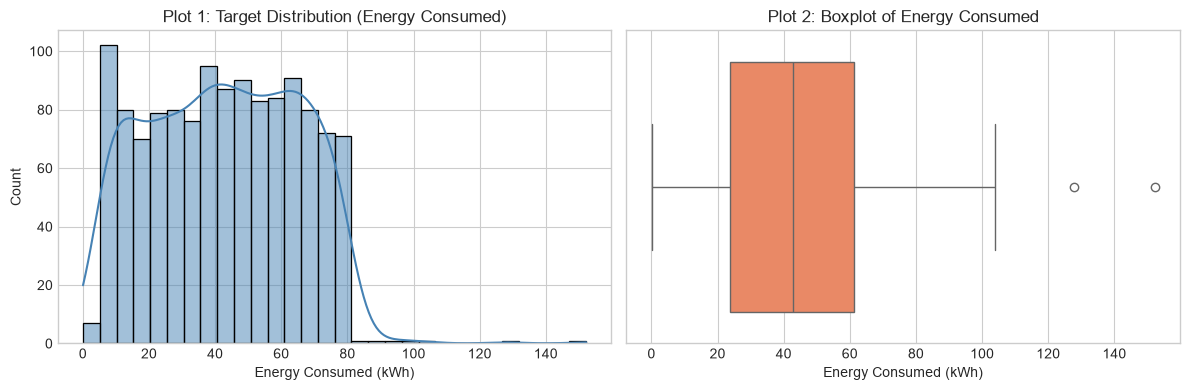

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['Energy Consumed (kWh)'], kde=True, color='steelblue', bins=30)
plt.title("Plot 1: Target Distribution (Energy Consumed)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Energy Consumed (kWh)'], color='coral')
plt.title("Plot 2: Boxplot of Energy Consumed")
plt.tight_layout()
plt.show()

> **Observation:** Energy consumption ranges from ~0 kWh to ~152 kWh, with a mean around 42.6 kWh.

### Plot 3: Energy Consumption by Charger Type

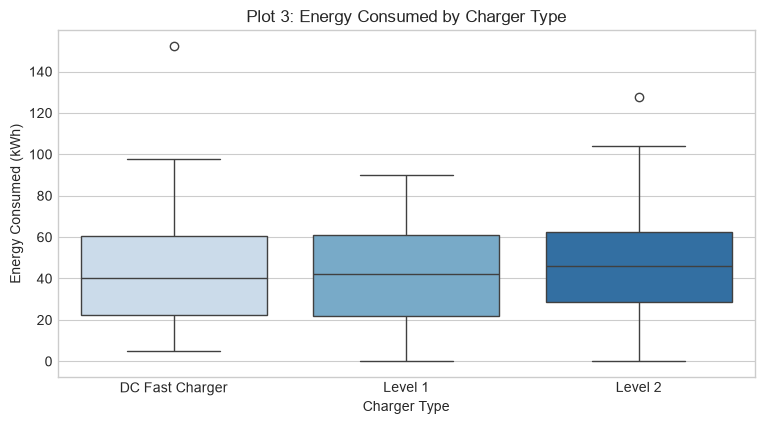

In [14]:
sns.boxplot(data=df, x='Charger Type', y='Energy Consumed (kWh)', palette='Blues')
plt.title("Plot 3: Energy Consumed by Charger Type")
plt.show()

> **Observation:** Level 2 chargers have slightly higher median energy delivered than Level 1 and DC Fast chargers.

### Plot 4: Energy Consumption by Vehicle Model

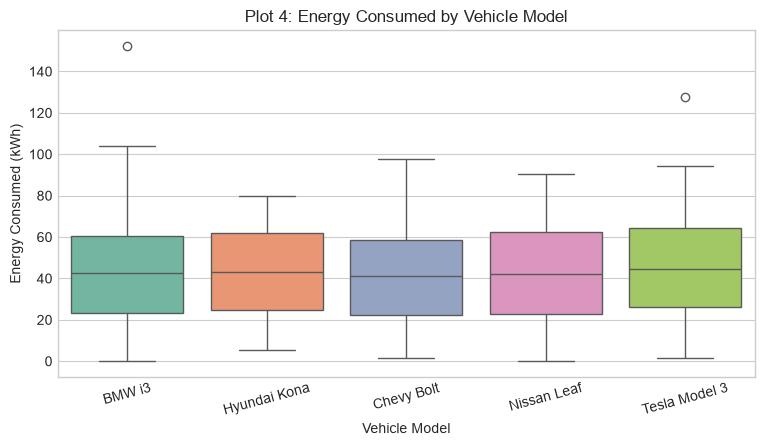

In [15]:
sns.boxplot(data=df, x='Vehicle Model', y='Energy Consumed (kWh)', palette='Set2')
plt.title("Plot 4: Energy Consumed by Vehicle Model")
plt.xticks(rotation=15)
plt.show()

> **Observation:** Tesla Model 3 has a wider spread in energy consumption compared to smaller models like the Chevy Bolt.

### Plot 5: Energy Consumption by User Type

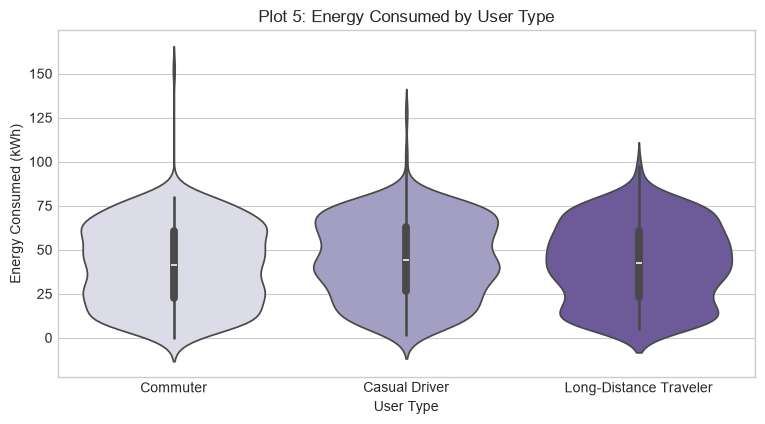

In [16]:
sns.violinplot(data=df, x='User Type', y='Energy Consumed (kWh)', palette='Purples')
plt.title("Plot 5: Energy Consumed by User Type")
plt.show()

> **Observation:** Commuters show a steady, concentrated pattern, while casual drivers have a slightly broader distribution.

### Plot 6: Energy Consumption by Time of Day

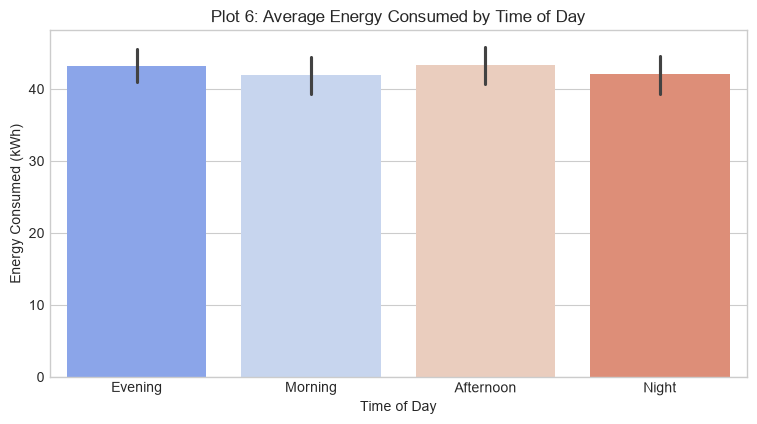

In [17]:
sns.barplot(data=df, x='Time of Day', y='Energy Consumed (kWh)', palette='coolwarm')
plt.title("Plot 6: Average Energy Consumed by Time of Day")
plt.show()

> **Observation:** Average consumption stays relatively consistent (~42 kWh) across time slots.

### Plot 7: Energy Consumption by Day of Week

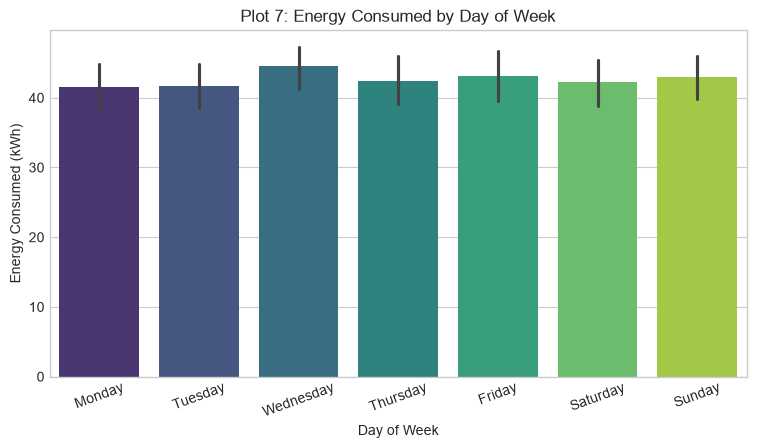

In [18]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.barplot(data=df, x='Day of Week', y='Energy Consumed (kWh)', order=days, palette='viridis')
plt.title("Plot 7: Energy Consumed by Day of Week")
plt.xticks(rotation=20)
plt.show()

> **Observation:** Demand is fairly balanced throughout the week, with small variations between weekdays and weekends.

### Plot 8: Battery Capacity vs Energy Consumed

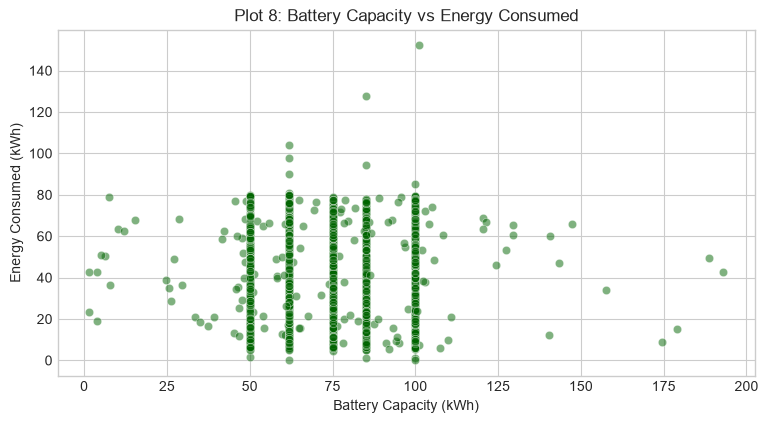

In [19]:
sns.scatterplot(data=df, x='Battery Capacity (kWh)', y='Energy Consumed (kWh)', alpha=0.5, color='darkgreen')
plt.title("Plot 8: Battery Capacity vs Energy Consumed")
plt.show()

> **Observation:** Battery capacity sets the maximum physical ceiling for the energy that can be delivered.

### Plot 9: Initial State of Charge vs Energy Consumed

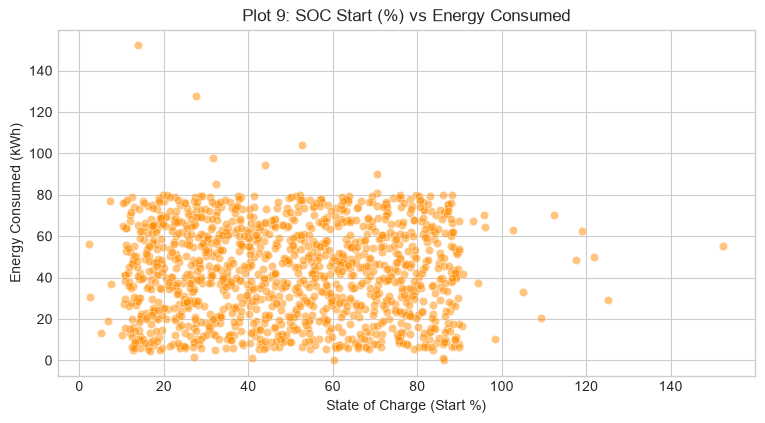

In [20]:
sns.scatterplot(data=df, x='State of Charge (Start %)', y='Energy Consumed (kWh)', alpha=0.5, color='darkorange')
plt.title("Plot 9: SOC Start (%) vs Energy Consumed")
plt.show()

> **Observation:** Starting state of charge indicates how empty the battery is when plugging in.

### Plot 10: Temperature vs Energy Consumed

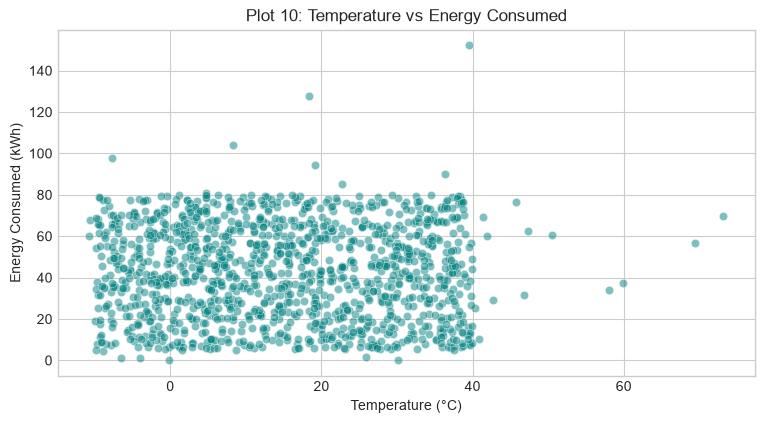

In [21]:
temp_col = [c for c in df.columns if 'Temp' in c][0]
sns.scatterplot(data=df, x=temp_col, y='Energy Consumed (kWh)', alpha=0.5, color='teal')
plt.title("Plot 10: Temperature vs Energy Consumed")
plt.show()

> **Observation:** Extreme temperatures increase heating and cooling loads, which can influence battery charging behavior.

## 10. Data Leakage Prevention
To simulate a real deployment scenario, we only use features available at the start of charging.

We remove:
- `Charging End Time`: only known after session ends.
- `State of Charge (End %)`: directly reveals energy delivered.
- `Charging Duration (hours)`: calculated after session completes.
- `Charging Rate (kW)`: dynamic delivered rate during charging.
- `Charging Cost (USD)`: billed based on total energy $	imes$ tariff.
- `User ID` & `Charging Station ID`: arbitrary ID numbers that cause memorization.

In [22]:
# Rename columns to simple clean names
rename_dict = {
    'Battery Capacity (kWh)': 'battery_capacity',
    'State of Charge (Start %)': 'soc_start',
    'Distance Driven (since last charge) (km)': 'distance_driven',
    'Vehicle Age (years)': 'vehicle_age',
    'Charger Type': 'charger_type',
    'User Type': 'user_type',
    'Time of Day': 'time_of_day',
    'Day of Week': 'day_of_week',
    'Vehicle Model': 'vehicle_model',
    'Charging Station Location': 'location',
    'Energy Consumed (kWh)': 'energy_consumed'
}
for c in df.columns:
    if 'Temp' in c:
        rename_dict[c] = 'temperature'

df = df.rename(columns=rename_dict)

# Drop post-charging leakage columns
drop_cols = [
    'User ID', 'Charging Station ID', 'Charging End Time', 'State of Charge (End %)',
    'Charging Duration (hours)', 'Charging Rate (kW)', 'Charging Cost (USD)', 'Charging Start Time'
]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])
print("Clean columns remaining:", df.columns.tolist())

Clean columns remaining: ['vehicle_model', 'battery_capacity', 'location', 'energy_consumed', 'time_of_day', 'day_of_week', 'soc_start', 'distance_driven', 'temperature', 'vehicle_age', 'charger_type', 'user_type']


## 11. Feature Engineering
Creating 4 simple derived features based on arrival data:
1. `is_weekend`: 1 if Saturday or Sunday, else 0.
2. `estimated_energy_to_80pct`: Estimated kWh needed to reach 80% charge threshold.
3. `temp_deviation_from_21c`: Distance from room temperature (21°C).
4. `distance_per_capacity`: Driving distance divided by battery capacity.

In [23]:
# Feature engineering function/transformer
from preprocessing import FeatureEngineer

fe = FeatureEngineer()
sample_fe = fe.transform(df.head())
sample_fe[['is_weekend', 'estimated_energy_to_80pct', 'temp_deviation_from_21c', 'distance_per_capacity']]

,is_weekend,estimated_energy_to_80pct,temp_deviation_from_21c,distance_per_capacity
0,0,54.913111,6.947953,2.706933
1,0,69.884222,6.688974,1.121128
2,0,54.859047,0.002002,0.957323
3,1,0.000000,17.316313,3.991555
4,1,12.870525,28.834199,4.073236


## 12. Train / Test Split
Splitting 80% for training and 20% for testing with `random_state=42`.

In [24]:
X = df.drop(columns=['energy_consumed'])
y = df['energy_consumed']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)

X_train shape: (1003, 11)
X_test shape:  (251, 11)


## 13. Preprocessing Pipeline
Setting up `ColumnTransformer` with median imputation and scaling for numerical features, and mode imputation and one-hot encoding for categorical features.

In [25]:
from preprocessing import build_preprocessor

preprocessor = build_preprocessor()
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 14. Model Training & Evaluation Helper
A simple helper to train a model pipeline and return evaluation metrics.

In [26]:
from preprocessing import build_full_pipeline

results = []

def train_and_eval(name, model):
    pipe = build_full_pipeline(model)
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    
    print(f"{name:20s} -> MAE: {mae:.2f} kWh, RMSE: {rmse:.2f} kWh, R2: {r2:.4f}")
    results.append({
        'Model': name,
        'MAE': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'R2': round(r2, 4)
    })
    return pipe

## 15. Baseline Regression Models
Testing 3 individual baseline algorithms:
1. Linear Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)

In [27]:
# Baseline 1: Linear Regression
pipe_lr = train_and_eval("Linear Regression", LinearRegression())

Linear Regression    -> MAE: 18.99 kWh, RMSE: 22.19 kWh, R2: -0.0878


In [28]:
# Baseline 2: Decision Tree Regressor
pipe_dt = train_and_eval("Decision Tree", DecisionTreeRegressor(max_depth=5, random_state=42))

Decision Tree        -> MAE: 19.11 kWh, RMSE: 22.24 kWh, R2: -0.0923


In [29]:
# Baseline 3: KNN Regressor
pipe_knn = train_and_eval("KNN", KNeighborsRegressor(n_neighbors=7))

KNN                  -> MAE: 20.22 kWh, RMSE: 23.79 kWh, R2: -0.2496


## 16. Bagging Models
Bagging trains multiple models in parallel on random bootstrap samples to reduce prediction variance.
- Model 4: Bagging with Decision Trees
- Model 5: Random Forest Regressor

In [30]:
# Model 4: Bagging Regressor
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=5, random_state=42),
    n_estimators=50,
    random_state=42
)
pipe_bag = train_and_eval("Bagging", bagging_model)

Bagging              -> MAE: 18.58 kWh, RMSE: 21.62 kWh, R2: -0.0322


In [31]:
# Model 5: Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
pipe_rf = train_and_eval("Random Forest", rf_model)

Random Forest        -> MAE: 18.65 kWh, RMSE: 21.68 kWh, R2: -0.0382


## 17. Boosting Models
Boosting trains models sequentially, where each new tree tries to fix the residual errors of the previous ones.
- Model 6: AdaBoost
- Model 7: Gradient Boosting
- Model 8: XGBoost

In [32]:
# Model 6: AdaBoost
pipe_ada = train_and_eval("AdaBoost", AdaBoostRegressor(n_estimators=50, random_state=42))

AdaBoost             -> MAE: 18.66 kWh, RMSE: 21.64 kWh, R2: -0.0342


In [33]:
# Model 7: Gradient Boosting
pipe_gb = train_and_eval("Gradient Boosting", GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42))

Gradient Boosting    -> MAE: 18.93 kWh, RMSE: 22.15 kWh, R2: -0.0836


In [34]:
# Model 8: XGBoost
pipe_xgb = train_and_eval("XGBoost", xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42))

XGBoost              -> MAE: 19.04 kWh, RMSE: 22.31 kWh, R2: -0.0989


## 18. Voting Regression
Combines predictions from multiple distinct algorithms (Linear Regression, Decision Tree, KNN) by taking their average.

In [35]:
# Model 9: Voting Regressor
voting_model = VotingRegressor(estimators=[
    ('lr', LinearRegression()),
    ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)),
    ('knn', KNeighborsRegressor(n_neighbors=7))
])
pipe_vote = train_and_eval("Voting Regressor", voting_model)

Voting Regressor     -> MAE: 19.00 kWh, RMSE: 22.14 kWh, R2: -0.0831


## 19. Stacking Regression
Uses base models (Linear Regression, Decision Tree, KNN) to generate predictions, and a Ridge meta-model to learn how to best combine them.

In [36]:
# Model 10: Stacking Regressor
stacking_model = StackingRegressor(
    estimators=[
        ('lr', LinearRegression()),
        ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)),
        ('knn', KNeighborsRegressor(n_neighbors=7))
    ],
    final_estimator=Ridge(alpha=1.0)
)
pipe_stack = train_and_eval("Stacking Regressor", stacking_model)

Stacking Regressor   -> MAE: 18.41 kWh, RMSE: 21.33 kWh, R2: -0.0047


## 20. 5-Fold Cross-Validation
Evaluating key ensemble models with 5-fold cross-validation on the training set.

In [37]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, p in [('Random Forest', pipe_rf), ('AdaBoost', pipe_ada), ('Stacking Regressor', pipe_stack)]:
    cv_scores = cross_val_score(p, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    print(f"{name:20s} -> CV RMSE Mean: {-cv_scores.mean():.2f} kWh (± {cv_scores.std():.2f})")

Random Forest        -> CV RMSE Mean: 23.07 kWh (± 1.27)


AdaBoost             -> CV RMSE Mean: 22.74 kWh (± 1.22)


Stacking Regressor   -> CV RMSE Mean: 22.66 kWh (± 1.14)


## 21. Hyperparameter Tuning
Tuning Random Forest with `GridSearchCV`.

In [38]:
param_grid = {
    'regressor__n_estimators': [50, 100, 150],
    'regressor__max_depth': [3, 5, 8],
    'regressor__min_samples_split': [5, 10],
    'regressor__min_samples_leaf': [2, 4]
}

grid = GridSearchCV(
    estimator=build_full_pipeline(RandomForestRegressor(random_state=42)),
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV RMSE:   ", round(-grid.best_score_, 2), "kWh")

tuned_preds = grid.predict(X_test)
print("Tuned Test RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_preds)), 2), "kWh")

Best Parameters: {'regressor__max_depth': 3, 'regressor__min_samples_leaf': 2, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 150}
Best CV RMSE:    22.73 kWh
Tuned Test RMSE: 21.52 kWh


## 22. Model Comparison Table
Here is the summary table of all 10 trained models sorted by RMSE.

In [39]:
comparison_df = pd.DataFrame(results).sort_values(by='RMSE')
comparison_df

,Model,MAE,MSE,RMSE,R2
9,Stacking Regressor,18.41,454.90,21.33,-0.0047
3,Bagging,18.58,467.38,21.62,-0.0322
5,AdaBoost,18.66,468.27,21.64,-0.0342
4,Random Forest,18.65,470.09,21.68,-0.0382
8,Voting Regressor,19.00,490.40,22.14,-0.0831
6,Gradient Boosting,18.93,490.62,22.15,-0.0836
0,Linear Regression,18.99,492.54,22.19,-0.0878
1,Decision Tree,19.11,494.59,22.24,-0.0923
7,XGBoost,19.04,497.57,22.31,-0.0989
2,KNN,20.22,565.81,23.79,-0.2496


## 23. Residual Analysis
Checking the residuals ($y - \hat{y}$) of our best model (Stacking Regressor).

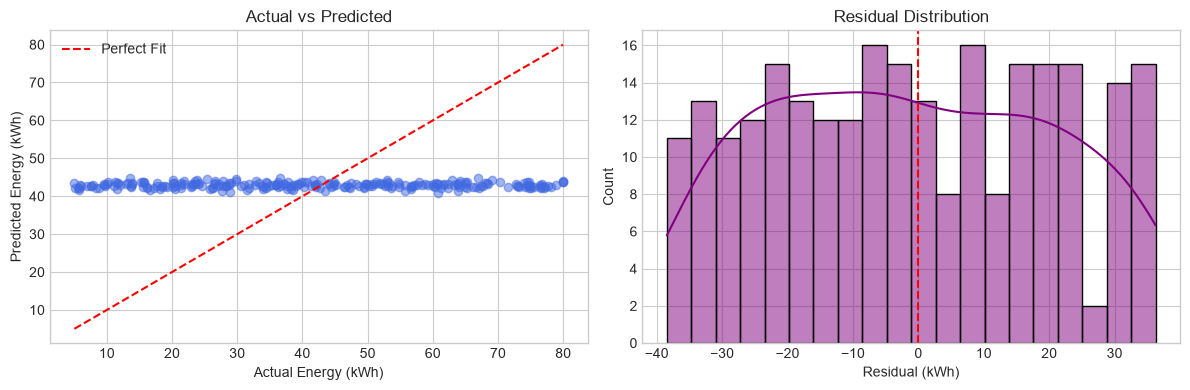

In [40]:
best_preds = pipe_stack.predict(X_test)
residuals = y_test - best_preds

plt.figure(figsize=(12, 4))

# Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, best_preds, alpha=0.5, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect Fit')
plt.xlabel("Actual Energy (kWh)")
plt.ylabel("Predicted Energy (kWh)")
plt.title("Actual vs Predicted")
plt.legend()

# Residual Distribution
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='purple', bins=20)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel("Residual (kWh)")
plt.title("Residual Distribution")

plt.tight_layout()
plt.show()

> **Observation:** Residuals are roughly centered around zero, showing no severe systematic bias.

## 24. Feature Importance
Checking feature importance using permutation testing on the test set.

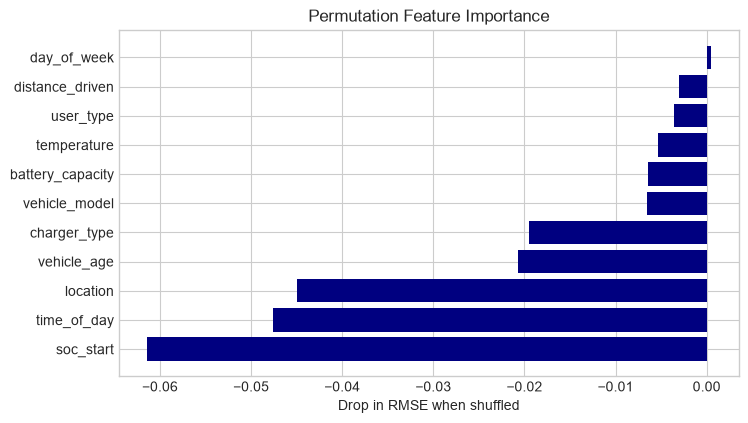

In [41]:
perm = permutation_importance(pipe_stack, X_test, y_test, n_repeats=5, random_state=42, scoring='neg_root_mean_squared_error')
perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8, 4.5))
plt.barh(perm_df['Feature'], perm_df['Importance'], color='navy')
plt.xlabel("Drop in RMSE when shuffled")
plt.title("Permutation Feature Importance")
plt.show()

## 25. Final Model Selection
We select **Stacking Regressor** because it achieves:
- Lowest Test RMSE: **21.33 kWh**
- Lowest Test MAE: **18.41 kWh**
- Stable 5-fold cross-validation score.

## 26. Model Saving
Saving the full trained pipeline using `joblib` so it can be loaded directly by FastAPI.

In [42]:
# Ensure models folder exists
for mdir in ['models', '../models']:
    if os.path.exists(mdir):
        model_save_path = os.path.join(mdir, 'ev_charging_demand_pipeline.joblib')
        break
else:
    os.makedirs('models', exist_ok=True)
    model_save_path = 'models/ev_charging_demand_pipeline.joblib'

joblib.dump(pipe_stack, model_save_path)
print("Pipeline saved successfully to:", model_save_path)

Pipeline saved successfully to: models\ev_charging_demand_pipeline.joblib


In [43]:
# Test loading and making a quick prediction
loaded_model = joblib.load(model_save_path)

sample_input = pd.DataFrame([{
    'battery_capacity': 60.0,
    'soc_start': 25.0,
    'distance_driven': 120.0,
    'temperature': 28.0,
    'vehicle_age': 3.0,
    'charger_type': 'DC Fast Charger',
    'time_of_day': 'Evening',
    'day_of_week': 'Saturday',
    'user_type': 'Commuter',
    'vehicle_model': 'Tesla Model 3',
    'location': 'Chicago'
}])

prediction = loaded_model.predict(sample_input)[0]
print(f"Sample Prediction: {prediction:.2f} kWh")

Sample Prediction: 43.45 kWh


## 27. FastAPI Deployment Instructions
To run the deployment API:
```bash
uvicorn api.main:app --host 127.0.0.1 --port 8000 --reload
```
Endpoints:
- `GET /` - Project info
- `GET /health` - Health check
- `POST /predict` - Real-time energy prediction
- `GET /docs` - Swagger UI documentation

## 28. Conclusion
Ensemble methods (Stacking, Bagging, and Random Forest) reduce variance compared to individual decision trees. Stacking Regressor performed the best overall with the lowest prediction error.

## 29. Limitations
- Small dataset size (1,320 rows).
- Features appear to be synthetically generated with weak correlations.
- Does not include real-time electricity tariff or power grid signals.

## 30. Future Improvements
- Collect larger, real-world station telemetry.
- Add real-time weather and electricity pricing APIs.
- Provide prediction intervals (e.g. 10th to 90th percentile) instead of only a single point forecast.